# ******Project 1: E-commerce Sales Data Analysis Using Python******

Let's perform Exploratory Data Analysis (EDA) on your Ecommerce Online Retail  dataset using Python, Pandas, NumPy, Matplotlib, and Seaborn.

We'll investigate the actual data, identify data quality problems, discover business patterns, calculate KPIs, 
and create visualizations. Since this dataset has over one million rows, we'll use efficient Pandas operations.

# ***E-commerce Sales Data Analysis Using Python***

In [ ]:
#Import the libraries..


Why do we use these libraries?
 
    Pandas	   -    Loading, cleaning, filtering, and grouping data
    NumPy	   -    Numerical calculations and array operations
    Matplotlib -	Creating and customizing charts
    Seaborn	   -    Creating statistical visualizations

In [8]:
# Install the openpyxl library in the current Jupyter Notebook environment.
# openpyxl allows Python and Pandas to read Excel (.xlsx) files.
%pip install openpyxl


[notice] A new release of pip is available: 26.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
# Import Pandas for data analysis
import pandas as pd

# Import NumPy for numerical operations
import numpy as np

# Import Matplotlib for visualization
import matplotlib.pyplot as plt

# Import Seaborn for statistical visualization
import seaborn as sns

# Set a consistent chart style
sns.set_theme(style="whitegrid")

In [11]:
#Load the dataset..
# Load the Excel dataset

df = pd.read_excel("ecommerce.xlsx")
#df is a common variable name for a Pandas DataFrame. A DataFrame stores data in rows and columns, similar to a spreadsheet.

# Display the first five rows
print(df.head())
print(df.head(10))
print(df.tail())

  Invoice StockCode                          Description  Quantity  \
0  489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1  489434    79323P                   PINK CHERRY LIGHTS        12   
2  489434    79323W                  WHITE CHERRY LIGHTS        12   
3  489434     22041         RECORD FRAME 7" SINGLE SIZE         48   
4  489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24   

          InvoiceDate  Price  Customer ID         Country  
0 2009-12-01 07:45:00   6.95      13085.0  United Kingdom  
1 2009-12-01 07:45:00   6.75      13085.0  United Kingdom  
2 2009-12-01 07:45:00   6.75      13085.0  United Kingdom  
3 2009-12-01 07:45:00   2.10      13085.0  United Kingdom  
4 2009-12-01 07:45:00   1.25      13085.0  United Kingdom  
  Invoice StockCode                          Description  Quantity  \
0  489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1  489434    79323P                   PINK CHERRY LIGHTS        12   
2  489434

In [12]:
#Understand the dataset structure..
#Check the number of rows and columns...
print("Dataset shape:", df.shape)

print("Total rows:", df.shape[0])

print("Total columns:", df.shape[1])

#df.shape returns a tuple containing the number of rows and columns.

#df.shape[0] gives the number of rows.

#df.shape[1] gives the number of columns.

Dataset shape: (525461, 8)
Total rows: 525461
Total columns: 8


In [13]:
#Display column names...
print(df.columns.tolist())

['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


In [15]:
display(df.columns.tolist())

['Invoice',
 'StockCode',
 'Description',
 'Quantity',
 'InvoiceDate',
 'Price',
 'Customer ID',
 'Country']

In [17]:
#Check data types and missing values

# This displays:
# - Column names
# - Number of non-missing values
# - Data types such as int64, float64, and object
# - Approximate memory usage



In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[us]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 32.1+ MB


In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[us]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 32.1+ MB


In [15]:
#Generate statistical summaries..
print(df.describe())



            Quantity                 InvoiceDate          Price    Customer ID
count  525461.000000                      525461  525461.000000  417534.000000
mean       10.337667  2010-06-28 11:37:36.845018       4.688834   15360.645478
min     -9600.000000         2009-12-01 07:45:00  -53594.360000   12346.000000
25%         1.000000         2010-03-21 12:20:00       1.250000   13983.000000
50%         3.000000         2010-07-06 09:51:00       2.100000   15311.000000
75%        10.000000         2010-10-15 12:45:00       4.210000   16799.000000
max     19152.000000         2010-12-09 20:01:00   25111.090000   18287.000000
std       107.424110                         NaN     146.126914    1680.811316


In [18]:
# Inspect missing values
# # Real-world datasets often contain missing values. Let's investigate them without deleting anything.
# Count missing values in every column

# Why is this important?
# If customer IDs are missing, we may not be able to connect those transactions to specific customers.
# However, those sales may still be useful when calculating overall revenue.
# Do not remove missing values until you understand how they affect the analysis.
# Count missing values in each column
# Count missing values in every column
missing_count = df.isna().sum()

# Calculate the percentage of missing values in every column
missing_percentage = (
    df.isna().sum() / len(df) * 100
).round(4)

# Create a DataFrame containing missing-value statistics
missing_report = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percentage": missing_percentage
})

# Sort columns by the number of missing values
missing_report = missing_report.sort_values(
    by="Missing_Count",
    ascending=False
)

# Display the missing-value report
print(missing_report)

             Missing_Count  Missing_Percentage
Customer ID         107927             20.5395
Description           2928              0.5572
Invoice                  0              0.0000
StockCode                0              0.0000
Quantity                 0              0.0000
InvoiceDate              0              0.0000
Price                    0              0.0000
Country                  0              0.0000


In [22]:
#Detect duplicate records...
# Count the number of completely duplicated rows
duplicate_count = df.duplicated().sum()

# Display the duplicate count
print("Total duplicate rows:", duplicate_count)

# # Display the first few duplicate rows
duplicates = df[df.duplicated(keep=False)]
# Display the first 10 rows...
print(duplicates.head(10))

Total duplicate rows: 6865
    Invoice StockCode                        Description  Quantity  \
362  489517     21913     VINTAGE SEASIDE JIGSAW PUZZLES         1   
363  489517     21912           VINTAGE SNAKES & LADDERS         1   
365  489517     21821   GLITTER STAR GARLAND WITH BELLS          1   
367  489517     22319  HAIRCLIPS FORTIES FABRIC ASSORTED        12   
368  489517     22130   PARTY CONE CHRISTMAS DECORATION          6   
371  489517     21912           VINTAGE SNAKES & LADDERS         1   
379  489517     21491    SET OF THREE VINTAGE GIFT WRAPS         1   
383  489517     22130   PARTY CONE CHRISTMAS DECORATION          6   
384  489517     22319  HAIRCLIPS FORTIES FABRIC ASSORTED        12   
385  489517     21913     VINTAGE SEASIDE JIGSAW PUZZLES         1   

            InvoiceDate  Price  Customer ID         Country  
362 2009-12-01 11:34:00   3.75      16329.0  United Kingdom  
363 2009-12-01 11:34:00   3.75      16329.0  United Kingdom  
365 2009-12-01 1

In [29]:
#Check data types and incorrect values....
# Display the data type of every column
print(df.dtypes)

# Display detailed information about the dataset
df.info()

Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[us]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 32.1+ MB


In [23]:
#In the retail dataset, dates should be datetime values, quantities should be numeric, and prices should be numeric...
# Check whether InvoiceDate is stored as a datetime type
print("InvoiceDate data type:", df["InvoiceDate"].dtype)

# Check the data types of Quantity and Price
print("Quantity data type:", df["Quantity"].dtype)
print("Price data type:", df["Price"].dtype)

# Count missing values in key columns
print("\nMissing key values:")
print(
    df[["Invoice", "InvoiceDate", "Quantity", "Price"]]
    .isna()
    .sum()
)

InvoiceDate data type: datetime64[us]
Quantity data type: int64
Price data type: float64

Missing key values:
Invoice        0
InvoiceDate    0
Quantity       0
Price          0
dtype: int64


In [24]:
#Identify negative quantities and invalid prices
#In this dataset, negative quantities may represent returns or cancellations. They are not necessarily errors....
# Count rows with negative quantities
negative_quantity_count = (df["Quantity"] < 0).sum()

# Count rows with zero quantities
zero_quantity_count = (df["Quantity"] == 0).sum()

# Count rows with negative prices
negative_price_count = (df["Price"] < 0).sum()

# Count rows with zero prices
zero_price_count = (df["Price"] == 0).sum()

# Print the results
print("Negative quantities:", negative_quantity_count)
print("Zero quantities:", zero_quantity_count)
print("Negative prices:", negative_price_count)
print("Zero prices:", zero_price_count)

Negative quantities: 12326
Zero quantities: 0
Negative prices: 3
Zero prices: 3687


In [26]:
#Inspect suspicious records.....
# Business interpretation:
# - Negative quantities may indicate returned goods.
# - Zero prices may reflect free items, promotional transactions, or data issues.
# - Negative prices need investigation before being included in revenue calculations.
# Display transactions with negative quantities
negative_sales = df[df["Quantity"] < 0]

print("Negative quantity examples:")
print(negative_sales.head(5))

# Display transactions with zero or negative prices
invalid_prices = df[df["Price"] <= 0]

print("\nZero or negative price examples:")
print(invalid_prices.head(5))
print(invalid_prices.tail(5))

Negative quantity examples:
     Invoice StockCode                    Description  Quantity  \
178  C489449     22087       PAPER BUNTING WHITE LACE       -12   
179  C489449    85206A   CREAM FELT EASTER EGG BASKET        -6   
180  C489449     21895  POTTING SHED SOW 'N' GROW SET        -4   
181  C489449     21896             POTTING SHED TWINE        -6   
182  C489449     22083     PAPER CHAIN KIT RETRO SPOT       -12   

            InvoiceDate  Price  Customer ID    Country  
178 2009-12-01 10:33:00   2.95      16321.0  Australia  
179 2009-12-01 10:33:00   1.65      16321.0  Australia  
180 2009-12-01 10:33:00   4.25      16321.0  Australia  
181 2009-12-01 10:33:00   2.10      16321.0  Australia  
182 2009-12-01 10:33:00   2.95      16321.0  Australia  

Zero or negative price examples:
     Invoice StockCode   Description  Quantity         InvoiceDate  Price  \
263   489464     21733  85123a mixed       -96 2009-12-01 10:52:00    0.0   
283   489463     71477         short   

In [27]:
#Creating a combined data-quality report.....
# Create a summary report for the dataset
quality_report = pd.DataFrame({
    "Metric": [
        "Total Rows",
        "Total Columns",
        "Duplicate Rows",
        "Rows with Missing Values",
        "Negative Quantities",
        "Zero Quantities",
        "Negative Prices",
        "Zero Prices"
    ],
    "Count": [
        len(df),
        df.shape[1],
        df.duplicated().sum(),
        df.isna().any(axis=1).sum(),
        (df["Quantity"] < 0).sum(),
        (df["Quantity"] == 0).sum(),
        (df["Price"] < 0).sum(),
        (df["Price"] == 0).sum()
    ]
})

# Display the final report
print(quality_report)
display(quality_report)

                     Metric   Count
0                Total Rows  525461
1             Total Columns       8
2            Duplicate Rows    6865
3  Rows with Missing Values  107927
4       Negative Quantities   12326
5           Zero Quantities       0
6           Negative Prices       3
7               Zero Prices    3687


,Metric,Count
0,Total Rows,525461
1,Total Columns,8
2,Duplicate Rows,6865
3,Rows with Missing Values,107927
4,Negative Quantities,12326
5,Zero Quantities,0
6,Negative Prices,3
7,Zero Prices,3687


# **Data Cleaning and Preprocessing**....

# By the end of this lesson, you will learn to:
# - Create a safe working copy of the original dataset.
# - Standardize column names.
# - Handle missing values appropriately.
# - Remove confirmed duplicate records.
# - Correct data types.
# - Identify invalid quantities and prices.
# - Create useful columns for sales analysis.
#  - Save the cleaned dataset.

In [36]:
#Load libraries and the dataset...
# Import Pandas for working with tabular data
import pandas as pd

# Import NumPy for numerical calculations and missing-value handling
import numpy as np

# Import Matplotlib for creating charts
import matplotlib.pyplot as plt

# Import Seaborn for statistical visualizations
import seaborn as sns

# Set the default style for charts
sns.set_theme(style="whitegrid")

# Load the original Excel dataset
df = pd.read_excel("ecommerce.xlsx")

# Display the first five rows to verify that loading succeeded
print(df.head())

# Display the number of rows and columns
print("Original dataset shape:", df.shape)

  Invoice StockCode                          Description  Quantity  \
0  489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1  489434    79323P                   PINK CHERRY LIGHTS        12   
2  489434    79323W                  WHITE CHERRY LIGHTS        12   
3  489434     22041         RECORD FRAME 7" SINGLE SIZE         48   
4  489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24   

          InvoiceDate  Price  Customer ID         Country  
0 2009-12-01 07:45:00   6.95      13085.0  United Kingdom  
1 2009-12-01 07:45:00   6.75      13085.0  United Kingdom  
2 2009-12-01 07:45:00   6.75      13085.0  United Kingdom  
3 2009-12-01 07:45:00   2.10      13085.0  United Kingdom  
4 2009-12-01 07:45:00   1.25      13085.0  United Kingdom  
Original dataset shape: (525461, 8)


In [29]:
#Create a working copy...
# Create an independent working copy of the original dataset
clean_df = df.copy()

# Display the shape of the working copy
print("Working dataset shape:", clean_df.shape)

Working dataset shape: (525461, 8)


In [30]:
#Standardize column names....
# The dataset may contain column names with spaces, such as Customer ID. 
# We'll remove unwanted spaces around column names while keeping the original names recognizable.
# Remove leading and trailing spaces from every column name
clean_df.columns = clean_df.columns.str.strip()

# Display the cleaned column names
print(clean_df.columns.tolist())

['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


In [33]:
# Access the customer ID column using its exact name
print(clean_df["Customer ID"].head())
print(clean_df["Customer ID"].tail())

0    13085.0
1    13085.0
2    13085.0
3    13085.0
4    13085.0
Name: Customer ID, dtype: float64
525456    17530.0
525457    17530.0
525458    17530.0
525459    17530.0
525460    17530.0
Name: Customer ID, dtype: float64


In [43]:
# Handle missing values
# First, let's measure missing values before changing anything.
# Count missing values in each column
missing_counts = clean_df.isna().sum()

# Calculate the percentage of missing values in each column
missing_percentages = (
    clean_df.isna().sum() / len(clean_df) * 100
).round(2)

# Combine counts and percentages into a report
missing_report = pd.DataFrame({
    "Missing_Count": missing_counts,
    "Missing_Percentage": missing_percentages
})

# Sort the report from the most missing values to the fewest
missing_report = missing_report.sort_values(
    by="Missing_Count",
    ascending=False
)

# Display the report
print(missing_report)

             Missing_Count  Missing_Percentage
Customer ID         107927               20.54
Description           2928                0.56
Invoice                  0                0.00
StockCode                0                0.00
Quantity                 0                0.00
InvoiceDate              0                0.00
Price                    0                0.00
Country                  0                0.00


In [41]:
# Replace missing product descriptions with a clear label
clean_df["Description"] = clean_df["Description"].fillna("Unknown")

# Count missing customer IDs without removing their transactions
missing_customer_ids = clean_df["Customer ID"].isna().sum()

# Display the number of unidentified customers' transaction rows
print("Rows with missing Customer ID:", missing_customer_ids)

# Verify missing values remaining in the dataset
#print(clean_df.isna().sum())
print(clean_df.isna().sum())
#display(clean_df.isna().sum())

Rows with missing Customer ID: 107927
Invoice             0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
Price               0
Customer ID    107927
Country             0
dtype: int64


In [43]:
# #Remove confirmed duplicate records...
# Exact duplicate rows can inflate revenue and transaction counts.
# We'll remove repeated rows that match across all columns.
# Count exact duplicate rows before removing them
duplicates_before = clean_df.duplicated().sum()

# Display the number of duplicate rows found
print("Duplicates before cleaning:", duplicates_before)

# # Remove exact duplicate rows while keeping the first occurrence
clean_df = clean_df.drop_duplicates(keep="first")

# # Reset the row index after removing duplicates
clean_df = clean_df.reset_index(drop=True)

# # Count duplicates again to verify the result
duplicates_after = clean_df.duplicated().sum()

# # Display the results
print("Duplicates after cleaning:", duplicates_after)

# # Display the updated dataset shape
print("Dataset shape after duplicate removal:", clean_df.shape)

Duplicates before cleaning: 6865
Duplicates after cleaning: 0
Dataset shape after duplicate removal: (518596, 8)


In [44]:
#Correct data types....
# Convert invoice dates to datetime, marking unparseable dates as missing
clean_df["InvoiceDate"] = pd.to_datetime(
    clean_df["InvoiceDate"],
    errors="coerce"
)

# Convert quantities to numeric values
clean_df["Quantity"] = pd.to_numeric(
    clean_df["Quantity"],
    errors="coerce"
)

# Convert prices to numeric values
clean_df["Price"] = pd.to_numeric(
    clean_df["Price"],
    errors="coerce"
)

# Convert customer IDs to numeric values where possible
clean_df["Customer ID"] = pd.to_numeric(
    clean_df["Customer ID"],
    errors="coerce"
)

# Display the data types after conversion
print(clean_df.dtypes)

Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
dtype: object


In [47]:
#Convert customer IDs to nullable integers....
# Convert valid whole-number customer IDs to nullable integers
clean_df["Customer ID"] = clean_df["Customer ID"].astype("Int64")

# Display a few customer IDs
print(clean_df["Customer ID"].head())

# Verify the resulting customer ID data type
print("Customer ID type:", clean_df["Customer ID"].dtype)

0    13085
1    13085
2    13085
3    13085
4    13085
Name: Customer ID, dtype: Int64
Customer ID type: Int64


In [48]:
#Standardize text fields.....
# Product descriptions and country names may contain unnecessary spaces. 
# We'll clean whitespace without changing the meaning of the text.
# List the text columns that we want to standardize
text_columns = ["Invoice", "StockCode", "Description", "Country"]

# Loop through the selected columns
for column in text_columns:

    # Convert values to Pandas string type while preserving missing values
    clean_df[column] = clean_df[column].astype("string")

    # Remove spaces from the beginning and end of each text value
    clean_df[column] = clean_df[column].str.strip()

# Display a few standardized rows
print(clean_df[text_columns].head())

  Invoice StockCode                          Description         Country
0  489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS  United Kingdom
1  489434    79323P                   PINK CHERRY LIGHTS  United Kingdom
2  489434    79323W                  WHITE CHERRY LIGHTS  United Kingdom
3  489434     22041          RECORD FRAME 7" SINGLE SIZE  United Kingdom
4  489434     21232       STRAWBERRY CERAMIC TRINKET BOX  United Kingdom


In [49]:
#Remove rows missing essential transaction fields....
# Record the number of rows before removing incomplete transactions
rows_before = len(clean_df)

# Remove rows missing essential transaction fields
clean_df = clean_df.dropna(
    subset=["Invoice", "InvoiceDate", "Quantity", "Price"]
).copy()

# Reset the index after removing incomplete rows
clean_df = clean_df.reset_index(drop=True)

# Calculate how many rows were removed
rows_removed = rows_before - len(clean_df)

# Display the cleaning results
print("Rows before removing incomplete transactions:", rows_before)
print("Rows removed:", rows_removed)
print("Rows remaining:", len(clean_df))

Rows before removing incomplete transactions: 518596
Rows removed: 0
Rows remaining: 518596


In [50]:
#Investigate invalid prices and quantities.....
#A negative quantity may indicate a return or cancellation. 
#A zero price may represent a free promotional item. These records need investigation before deciding how to use them.


# Identify rows with zero or negative quantities
unusual_quantities = clean_df[
    clean_df["Quantity"] <= 0
]

# Identify rows with zero or negative prices
unusual_prices = clean_df[
    clean_df["Price"] <= 0
]

# Display the number of unusual quantity records
print("Rows with zero or negative quantity:", len(unusual_quantities))

# Display the number of unusual price records
print("Rows with zero or negative price:", len(unusual_prices))

# Display examples for manual investigation
print("\nUnusual quantity examples:")
print(unusual_quantities.head())

# Display examples of zero or negative prices
print("\nUnusual price examples:")
print(unusual_prices.head())

Rows with zero or negative quantity: 12302
Rows with zero or negative price: 3684

Unusual quantity examples:
     Invoice StockCode                    Description  Quantity  \
178  C489449     22087       PAPER BUNTING WHITE LACE       -12   
179  C489449    85206A   CREAM FELT EASTER EGG BASKET        -6   
180  C489449     21895  POTTING SHED SOW 'N' GROW SET        -4   
181  C489449     21896             POTTING SHED TWINE        -6   
182  C489449     22083     PAPER CHAIN KIT RETRO SPOT       -12   

            InvoiceDate  Price  Customer ID    Country  
178 2009-12-01 10:33:00   2.95        16321  Australia  
179 2009-12-01 10:33:00   1.65        16321  Australia  
180 2009-12-01 10:33:00   4.25        16321  Australia  
181 2009-12-01 10:33:00   2.10        16321  Australia  
182 2009-12-01 10:33:00   2.95        16321  Australia  

Unusual price examples:
     Invoice StockCode   Description  Quantity         InvoiceDate  Price  \
263   489464     21733  85123a mixed       

In [52]:
# Create new columns for analysis
# We can now calculate revenue for each transaction line and extract useful time features.
# Calculate transaction-line revenue
# Negative quantities will produce negative line revenue
clean_df["Revenue"] = clean_df["Quantity"] * clean_df["Price"]

# Extract the year from the invoice date
clean_df["Year"] = clean_df["InvoiceDate"].dt.year

# Extract the month number from the invoice date
clean_df["Month"] = clean_df["InvoiceDate"].dt.month

# Create a year-month column for monthly sales analysis
clean_df["YearMonth"] = clean_df["InvoiceDate"].dt.to_period("M").astype("string")

# Display the new columns for verification
print(
    clean_df[
        ["Invoice", "InvoiceDate", "Quantity", "Price", "Revenue", "Year", "Month", "YearMonth"]
    ].head(10)
)

  Invoice         InvoiceDate  Quantity  Price  Revenue  Year  Month YearMonth
0  489434 2009-12-01 07:45:00        12   6.95     83.4  2009     12   2009-12
1  489434 2009-12-01 07:45:00        12   6.75     81.0  2009     12   2009-12
2  489434 2009-12-01 07:45:00        12   6.75     81.0  2009     12   2009-12
3  489434 2009-12-01 07:45:00        48   2.10    100.8  2009     12   2009-12
4  489434 2009-12-01 07:45:00        24   1.25     30.0  2009     12   2009-12
5  489434 2009-12-01 07:45:00        24   1.65     39.6  2009     12   2009-12
6  489434 2009-12-01 07:45:00        24   1.25     30.0  2009     12   2009-12
7  489434 2009-12-01 07:45:00        10   5.95     59.5  2009     12   2009-12
8  489435 2009-12-01 07:46:00        12   2.55     30.6  2009     12   2009-12
9  489435 2009-12-01 07:46:00        12   3.75     45.0  2009     12   2009-12


In [53]:
#Separate positive sales from returns...
#For sales KPIs, we'll create a separate DataFrame containing positive quantities and positive prices...
#The cleaned dataset will still retain zero and negative quantities and prices for further investigation....
# Create a positive-sales dataset using valid positive quantities and prices
sales_df = clean_df[
    (clean_df["Quantity"] > 0) &
    (clean_df["Price"] > 0)
].copy()

# Create a separate dataset for negative-quantity transactions
returns_df = clean_df[
    clean_df["Quantity"] < 0
].copy()

# Display the number of rows in each dataset
print("All cleaned transactions:", len(clean_df))
print("Positive-sales records:", len(sales_df))
print("Negative-quantity records:", len(returns_df))

# Calculate the total positive-sales revenue
total_sales_revenue = sales_df["Revenue"].sum()

# Calculate the total units in positive-sales records
total_units_sold = sales_df["Quantity"].sum()

# Display the results
print(f"Positive-sales revenue: {total_sales_revenue:,.2f}")
print(f"Units in positive-sales records: {total_units_sold:,.0f}")

All cleaned transactions: 518596
Positive-sales records: 504731
Negative-quantity records: 12302
Positive-sales revenue: 10,272,136.23
Units in positive-sales records: 5,812,948


In [54]:
#Save the cleaned datasets...
#We'll save the files as CSV. 
#This format works well for large datasets and avoids Excel's worksheet row limit...
# Import Path to manage project folders
from pathlib import Path

# Create the outputs directory if it does not already exist
output_folder = Path("../outputs")
output_folder.mkdir(parents=True, exist_ok=True)

# Save all cleaned transactions, including records flagged for investigation
clean_df.to_csv(
    output_folder / "ecommerce_cleaned.csv",
    index=False
)

# Save positive-sales records for sales KPI analysis
sales_df.to_csv(
    output_folder / "ecommerce_positive_sales.csv",
    index=False
)

# Confirm that the files have been saved
print("Cleaned transactions saved successfully.")
print("Output folder:", output_folder.resolve())

Cleaned transactions saved successfully.
Output folder: /Users/suruchi/Desktop/Python_Dataanalysis/data_analysis_videos/outputs


In [55]:
#Final cleaning report....
# Create a summary of the original and cleaned datasets
cleaning_summary = pd.DataFrame({
    "Metric": [
        "Original rows",
        "Cleaned rows",
        "Rows removed",
        "Remaining duplicate rows",
        "Remaining rows with missing values"
    ],
    "Value": [
        len(df),
        len(clean_df),
        len(df) - len(clean_df),
        clean_df.duplicated().sum(),
        clean_df.isna().any(axis=1).sum()
    ]
})

# Display the final cleaning summary
print(cleaning_summary)

# Display the cleaned dataset's data types
print("\nFinal data types:")
print(clean_df.dtypes)

                               Metric   Value
0                       Original rows  525461
1                        Cleaned rows  518596
2                        Rows removed    6865
3            Remaining duplicate rows       0
4  Remaining rows with missing values  107833

Final data types:
Invoice                string
StockCode              string
Description            string
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID             Int64
Country                string
Revenue               float64
Year                    int32
Month                   int32
YearMonth              string
dtype: object


# **Exploratory Data Analysis (EDA) and Business KPIs**
**We'll use the cleaned data to calculate total revenue, orders, average order value, customer counts, monthly sales growth, top-selling products, and country-level performance. 
Then we'll visualize the findings using Matplotlib and Seaborn.**

In [57]:
#import dataset......
# Import Pandas for data analysis
import pandas as pd

# Import NumPy for numerical calculations
import numpy as np

# Import Matplotlib for creating charts
import matplotlib.pyplot as plt

# Import Seaborn for statistical visualizations
import seaborn as sns

# Set a consistent chart style
sns.set_theme(style="whitegrid")

# Load the cleaned positive-sales dataset
# parse_dates converts InvoiceDate into a date column
sales_df = pd.read_csv(
    "../outputs/ecommerce_positive_sales.csv",
    parse_dates=["InvoiceDate"]
)

# Display the first five records
print(sales_df.head())

# Display the number of rows and columns
print("Dataset shape:", sales_df.shape)

# Display the column names
print("Columns:", sales_df.columns.tolist())

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.
  Invoice StockCode                          Description  Quantity  \
0  489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1  489434    79323P                   PINK CHERRY LIGHTS        12   
2  489434    79323W                  WHITE CHERRY LIGHTS        12   
3  489434     22041          RECORD FRAME 7" SINGLE SIZE        48   
4  489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24   

          InvoiceDate  Price  Customer ID         Country  Revenue  Year  \
0 2009-12-01 07:45:00   6.95      13085.0  United Kingdom     83.4  2009   
1 2009-12-01 07:45:00   6.75      13085.0  United Kingdom     81.0  2009   
2 2009-12-01 07:45:00   6.75      13085.0  United Kingdom     81.0  2009   
3 2009-12-01 07:45:00   2.10      13085.0  United Kingdom    100.8  2009   
4 2009-12-01 07:45:00   1.25      13085.0  Un

/var/folders/ts/3rlmcq110z96z6tjzjkm17800000gn/T/ipykernel_67894/3670788646.py:19: DtypeWarning: Columns (0: Invoice) have mixed types. Specify dtype option on import or set low_memory=False.
  sales_df = pd.read_csv(


<!-- Calculate the main business KPIs
Let's calculate five important KPIs for the e-commerce business.
KPI	                   Meaning
Total revenue	           Total value of positive sales transactions
Units sold	               Total number of units sold
Total orders	            Number of distinct invoices in the positive-sales dataset
Average Order Value (AOV)	Average revenue per distinct invoice
Unique customers	        Number of distinct identified customers -->

<!-- Calculate the main business KPIs
Let's calculate five important KPIs for the e-commerce business.
KPI	Meaning
Total revenue	Total value of positive sales transactions
Units sold	Total number of units sold
Total orders	Number of distinct invoices in the positive-sales dataset
Average Order Value (AOV)	Average revenue per distinct invoice
Unique customers	Number of distinct identified customers -->


In [58]:
# Calculate the main business KPIs
# Let's calculate five important KPIs for the e-commerce business.
# KPI	Meaning
# Total revenue	Total value of positive sales transactions
# Units sold	Total number of units sold
# Total orders	Number of distinct invoices in the positive-sales dataset
# Average Order Value (AOV)	Average revenue per distinct invoice
# Unique customers	Number of distinct identified customers

In [59]:
#Calculate business KPIs....
# Calculate total revenue from positive sales
total_revenue = sales_df["Revenue"].sum()

# Calculate the total number of units sold
total_units_sold = sales_df["Quantity"].sum()

# Count distinct invoices as orders
total_orders = sales_df["Invoice"].nunique()

# Calculate average revenue per invoice
# Avoid division by zero if there are no orders
average_order_value = (
    total_revenue / total_orders if total_orders > 0 else 0
)

# Count distinct customers, excluding missing Customer IDs
unique_customers = sales_df["Customer ID"].nunique()

# Display all KPIs
print("ECOMMERCE BUSINESS KPIs")
print("-" * 35)

print(f"Total Revenue: {total_revenue:,.2f}")
print(f"Total Units Sold: {total_units_sold:,.0f}")
print(f"Total Orders: {total_orders:,}")
print(f"Average Order Value: {average_order_value:,.2f}")
print(f"Unique Identified Customers: {unique_customers:,}")

ECOMMERCE BUSINESS KPIs
-----------------------------------
Total Revenue: 10,272,136.23
Total Units Sold: 5,812,948
Total Orders: 20,953
Average Order Value: 490.25
Unique Identified Customers: 4,312


In [60]:
# Analyze monthly revenue
# A business needs to understand whether revenue is increasing or decreasing over time.
# We will group sales by month and create a line chart.

YearMonth
2009-12     822483.950
2010-01     651155.112
2010-02     551878.296
2010-03     830915.261
2010-04     678875.252
2010-05     657705.500
2010-06     749537.310
2010-07     648810.270
2010-08     695251.910
2010-09     921696.991
2010-10    1161902.220
2010-11    1464293.142
2010-12     437631.020
Name: Revenue, dtype: float64


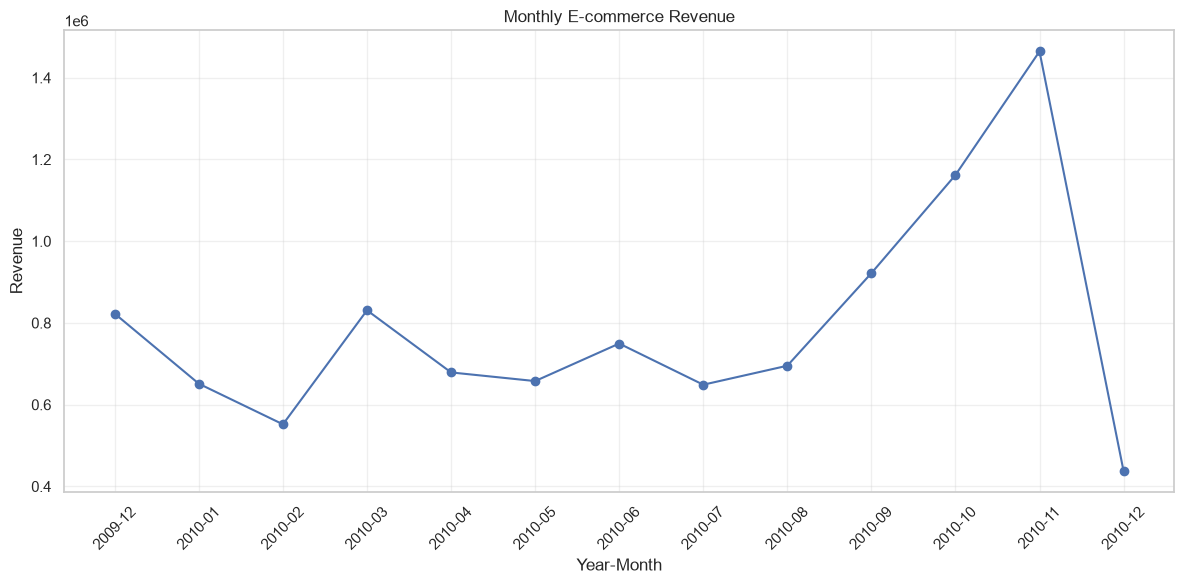

In [61]:
# Extract the year and month from each invoice date
sales_df["YearMonth"] = (
    sales_df["InvoiceDate"].dt.to_period("M").astype("string")
)

# Group transactions by month and calculate total revenue
monthly_revenue = (
    sales_df.groupby("YearMonth")["Revenue"]
    .sum()
    .sort_index()
)

# Display the monthly revenue values
print(monthly_revenue)

# Create a figure for the chart
plt.figure(figsize=(12, 6))

# Draw a line chart showing revenue by month
plt.plot(
    monthly_revenue.index,
    monthly_revenue.values,
    marker="o"
)

# Add a title and axis labels
plt.title("Monthly E-commerce Revenue")
plt.xlabel("Year-Month")
plt.ylabel("Revenue")

# Rotate month labels for readability
plt.xticks(rotation=45)

# Add grid lines
plt.grid(True, alpha=0.3)

# Adjust spacing to prevent labels from being cut off
plt.tight_layout()

# Display the chart
plt.show()

In [63]:
# Calculate month-over-month revenue growth
# Month-over-month (MoM) growth measures how much revenue changed compared with the previous month.
# The formula is:
# \[
# \text{MoM Growth (\%)}=
# \frac{\text{Current Revenue}-\text{Previous Revenue}}
# {\text{Previous Revenue}}\times100
# \]

In [64]:
# Create a DataFrame from the monthly revenue Series
monthly_analysis = monthly_revenue.to_frame(
    name="Revenue"
)

# Calculate the previous month's revenue
monthly_analysis["Previous_Month_Revenue"] = (
    monthly_analysis["Revenue"].shift(1)
)

# Calculate percentage growth compared with the previous month
# Replace zero previous-month revenue with NaN to avoid division by zero
previous_revenue = monthly_analysis["Previous_Month_Revenue"].replace(
    0, np.nan
)

monthly_analysis["MoM_Growth_Percent"] = (
    (
        monthly_analysis["Revenue"] - monthly_analysis["Previous_Month_Revenue"]
    ) / previous_revenue
) * 100

# Display revenue and growth together
print(monthly_analysis.round(2)) 

              Revenue  Previous_Month_Revenue  MoM_Growth_Percent
YearMonth                                                        
2009-12     822483.95                     NaN                 NaN
2010-01     651155.11               822483.95              -20.83
2010-02     551878.30               651155.11              -15.25
2010-03     830915.26               551878.30               50.56
2010-04     678875.25               830915.26              -18.30
2010-05     657705.50               678875.25               -3.12
2010-06     749537.31               657705.50               13.96
2010-07     648810.27               749537.31              -13.44
2010-08     695251.91               648810.27                7.16
2010-09     921696.99               695251.91               32.57
2010-10    1161902.22               921696.99               26.06
2010-11    1464293.14              1161902.22               26.03
2010-12     437631.02              1464293.14              -70.11


In [65]:
# - 10.00 means revenue increased by 10%.
# - -15.00 means revenue decreased by 15%.
# - NaN for the first month is expected because there is no earlier month to compare.

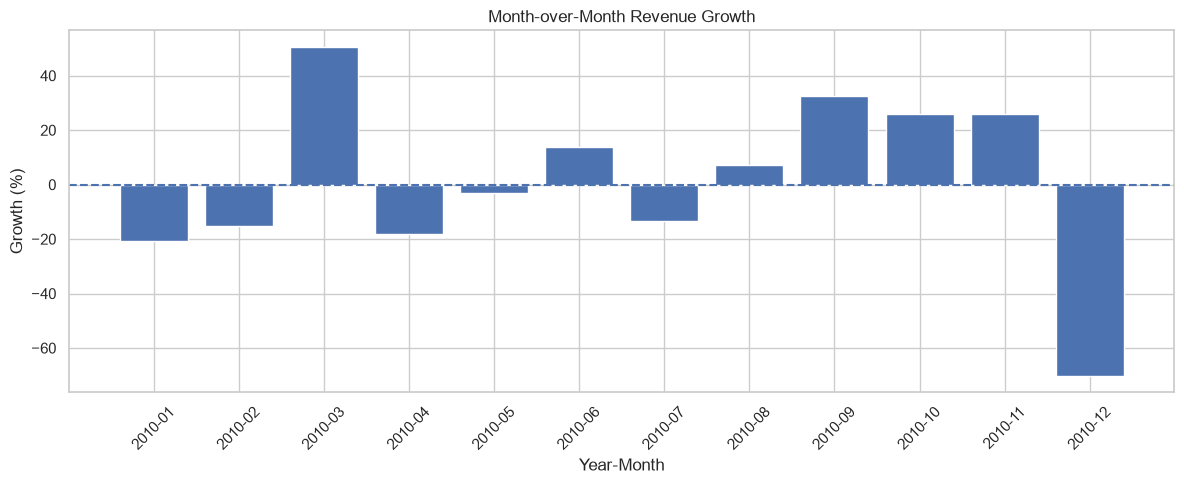

In [66]:
# Remove the first month and any undefined growth values
growth_data = monthly_analysis.dropna(
    subset=["MoM_Growth_Percent"]
)

# Create a figure for the growth chart
plt.figure(figsize=(12, 5))

# Plot monthly revenue growth as a bar chart
plt.bar(
    growth_data.index,
    growth_data["MoM_Growth_Percent"]
)

# Add a title and axis labels
plt.title("Month-over-Month Revenue Growth")
plt.xlabel("Year-Month")
plt.ylabel("Growth (%)")

# Draw a horizontal reference line at zero
plt.axhline(y=0, linestyle="--")

# Rotate month labels
plt.xticks(rotation=45)

# Adjust the layout and display the chart
plt.tight_layout()
plt.show()

TOP 10 PRODUCTS BY REVENUE
Description
Manual                                 262963.43
REGENCY CAKESTAND 3 TIER               169912.76
WHITE HANGING HEART T-LIGHT HOLDER     160345.63
DOTCOM POSTAGE                         116408.71
ASSORTED COLOUR BIRD ORNAMENT           72890.19
PAPER CHAIN KIT 50'S CHRISTMAS          58127.30
JUMBO BAG RED RETROSPOT                 56480.46
PARTY BUNTING                           49664.12
POSTAGE                                 49477.54
ROTATING SILVER ANGELS T-LIGHT HLDR     47954.49
Name: Revenue, dtype: float64


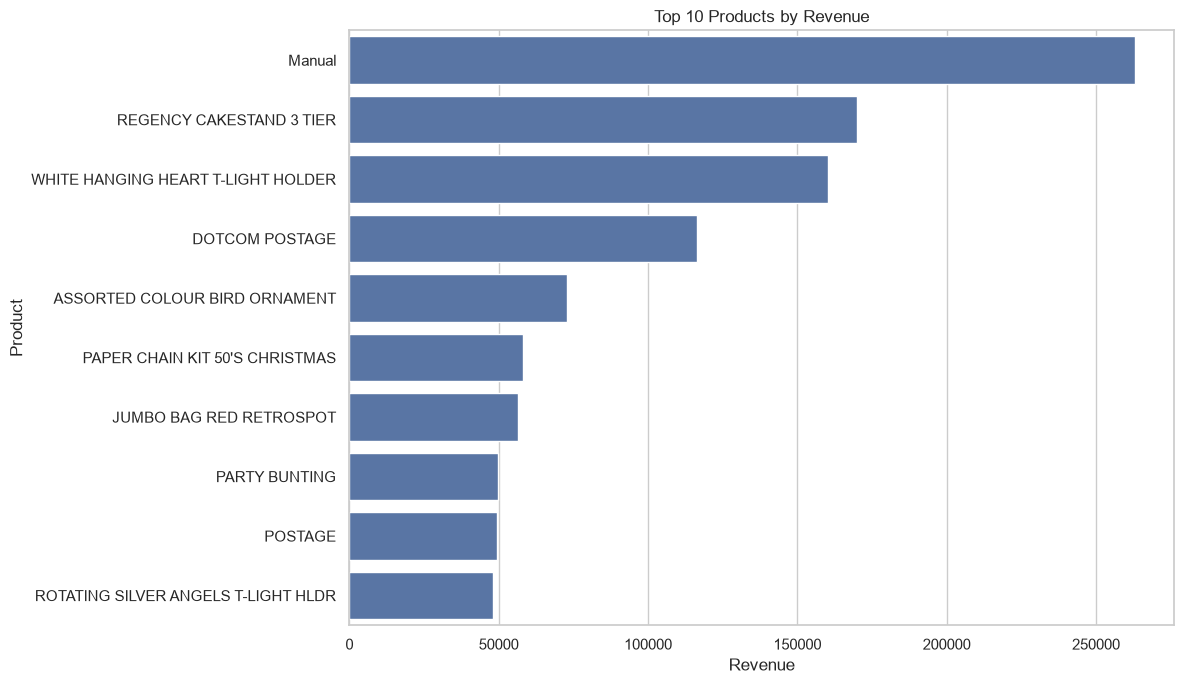

In [68]:
#. Find the top 10 products by revenue....
# Group sales by product description and sum the revenue
product_revenue = (
    sales_df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)


# Select the ten products with the highest revenue
top_10_products = product_revenue.head(10)

# Display the top ten products
print("TOP 10 PRODUCTS BY REVENUE")
print(top_10_products)

# Create a horizontal bar chart
plt.figure(figsize=(12, 7))

# Draw the chart with the highest-revenue product at the top
sns.barplot(
    x=top_10_products.values,
    y=top_10_products.index
)

# Add a title and axis labels
plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")

# Adjust spacing and display the chart
plt.tight_layout()
plt.show()

TOP 10 COUNTRIES BY REVENUE
Country
United Kingdom    8812685.403
EIRE               380909.570
Netherlands        268784.350
Germany            202025.391
France             147103.140
Sweden              53501.990
Denmark             50906.850
Spain               47568.650
Switzerland         43921.390
Australia           31446.800
Name: Revenue, dtype: float64


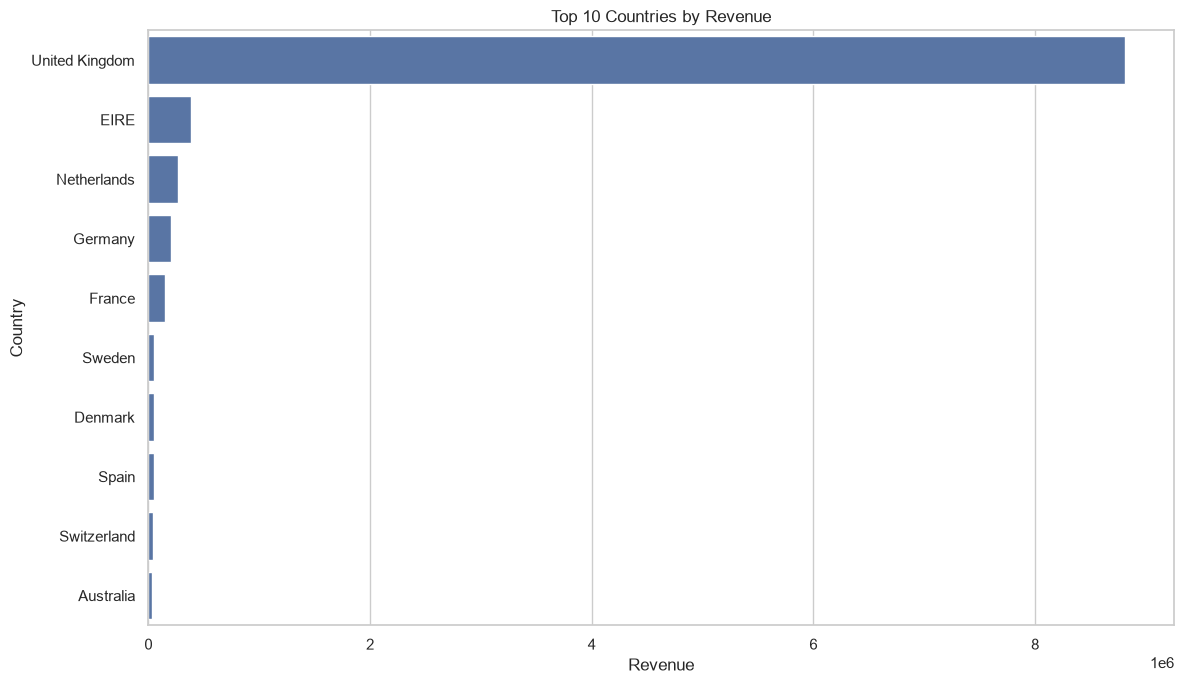

In [69]:
#Find the top 10 countries by revenue...
# Group transactions by country and calculate total revenue
country_revenue = (
    sales_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

# Select the ten countries with the highest revenue
top_10_countries = country_revenue.head(10)

# Display the results
print("TOP 10 COUNTRIES BY REVENUE")
print(top_10_countries)

# Create a horizontal bar chart
plt.figure(figsize=(12, 7))

# Visualize revenue by country
sns.barplot(
    x=top_10_countries.values,
    y=top_10_countries.index
)

# Add a title and axis labels
plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Country")

# Adjust the layout and display the chart
plt.tight_layout()
plt.show()

In [70]:
#Create a KPI summary table.....
# Create a dictionary containing the KPI names and their values
kpi_data = {
    "KPI": [
        "Total Revenue",
        "Total Units Sold",
        "Total Orders",
        "Average Order Value",
        "Unique Identified Customers"
    ],
    "Value": [
        total_revenue,
        total_units_sold,
        total_orders,
        average_order_value,
        unique_customers
    ]
}

# Convert the dictionary into a DataFrame
kpi_summary = pd.DataFrame(kpi_data)

# Display the KPI summary table
print(kpi_summary)

                           KPI         Value
0                Total Revenue  1.027214e+07
1             Total Units Sold  5.812948e+06
2                 Total Orders  2.095300e+04
3          Average Order Value  4.902466e+02
4  Unique Identified Customers  4.312000e+03


In [71]:
#Find the top 10 customers by revenue....
#Let's identify customers who have generated the highest total revenue....
# Remove records without a customer ID for customer-level analysis
customer_data = sales_df.dropna(
    subset=["Customer ID"]
).copy()

# Group transactions by customer
customer_revenue = (
    customer_data.groupby("Customer ID")
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Total_Units=("Quantity", "sum"),
        Total_Orders=("Invoice", "nunique")
    )
    .reset_index()
)

# Sort customers by revenue from highest to lowest
customer_revenue = customer_revenue.sort_values(
    "Total_Revenue",
    ascending=False
)

# Select the ten highest-revenue customers
top_10_customers = customer_revenue.head(10)

# Display the results
print(top_10_customers.round(2))

      Customer ID  Total_Revenue  Total_Units  Total_Orders
4183      18102.0      349164.35       124216            89
1637      14646.0      248396.50       170278            78
1269      14156.0      196549.74       108105           102
1840      14911.0      152121.22        69709           205
939       13694.0      131443.19       125893            94
3744      17511.0       84541.17        55107            31
1951      15061.0       83284.38        51791            86
3128      16684.0       80489.21        54555            27
3177      16754.0       65500.07        63551            29
4065      17949.0       60117.60        30112            74


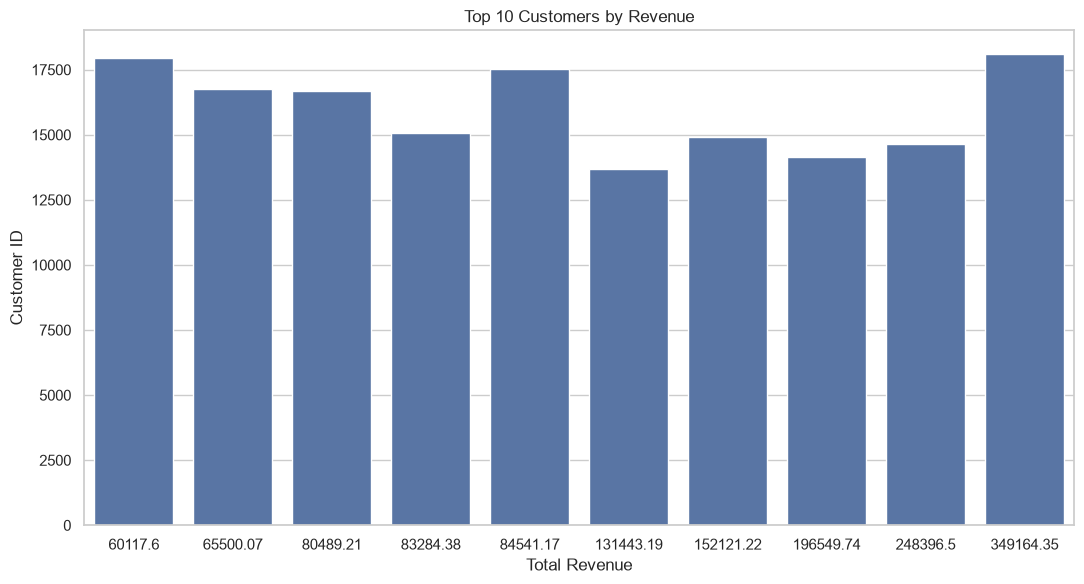

In [72]:
#Visualize the top customers....
# Create a figure for the chart
plt.figure(figsize=(11, 6))

# Draw a horizontal bar chart of customer revenue
sns.barplot(
    data=top_10_customers,
    x="Total_Revenue",
    y="Customer ID"
)

# Add a descriptive title and axis labels
plt.title("Top 10 Customers by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Customer ID")

# Adjust spacing
plt.tight_layout()

# Display the chart
plt.show()

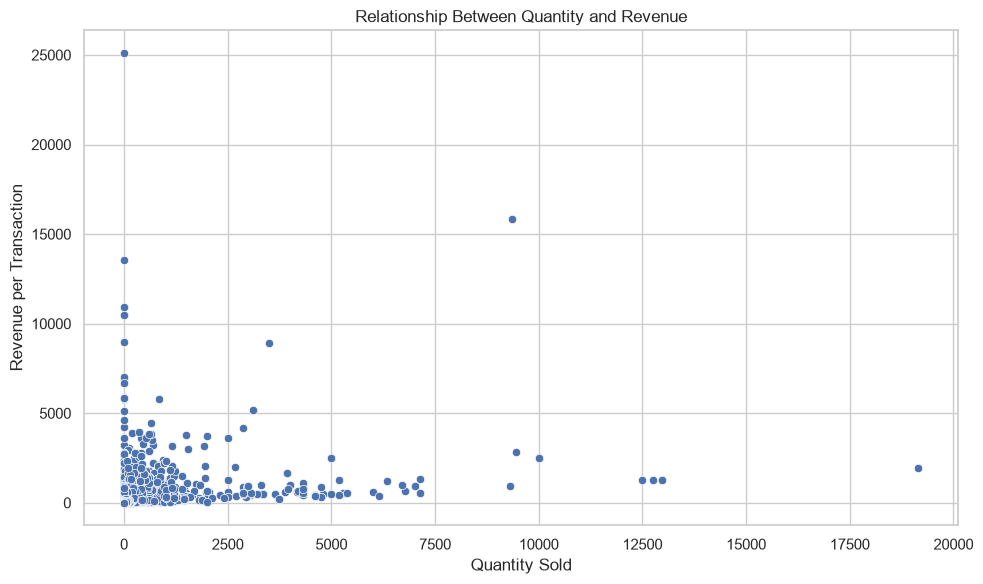

In [73]:
#Relationship between quantity and revenue.....
# Create a scatter plot comparing quantity and revenue
plt.figure(figsize=(10, 6))

# Plot each transaction as a point
sns.scatterplot(
    data=sales_df,
    x="Quantity",
    y="Revenue"
)

# Add a chart title
plt.title("Relationship Between Quantity and Revenue")

# Label the horizontal axis
plt.xlabel("Quantity Sold")

# Label the vertical axis
plt.ylabel("Revenue per Transaction")

# Improve spacing
plt.tight_layout()

# Display the chart
plt.show()

In [74]:
# Compare revenue and quantity by country
# A country may generate high revenue because customers purchase expensive products, large quantities, or both.
# Let's compare the top 10 countries by revenue.

In [75]:
# Group transactions by country and calculate total revenue
country_analysis = (
    sales_df.groupby("Country")
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Total_Units=("Quantity", "sum"),
        Total_Orders=("Invoice", "nunique")
    )
)

# Sort countries by total revenue
country_analysis = country_analysis.sort_values(
    "Total_Revenue",
    ascending=False
)

# Select the ten countries with the highest revenue
top_countries = country_analysis.head(10)

# Display the country-level summary
print(top_countries.round(2))

                Total_Revenue  Total_Units  Total_Orders
Country                                                 
United Kingdom     8812685.40      4702281         19291
EIRE                380909.57       193047           348
Netherlands         268784.35       183615           135
Germany             202025.39       108615           348
France              147103.14       163029           241
Sweden               53501.99        52555            69
Denmark              50906.85       229690            26
Spain                47568.65        22841            66
Switzerland          43921.39        22255            40
Australia            31446.80        20189            40


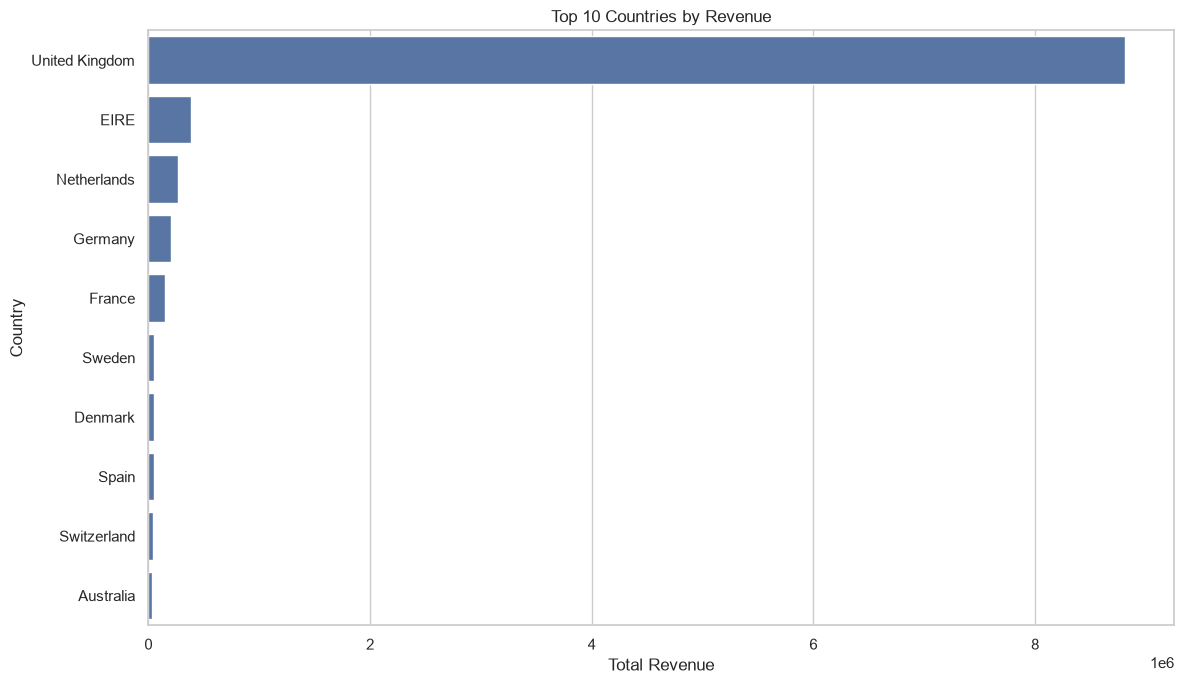

In [76]:
#Visualize revenue by country....
# Create a figure for the country comparison
plt.figure(figsize=(12, 7))

# Plot total revenue for the top 10 countries
sns.barplot(
    data=top_countries.reset_index(),
    x="Total_Revenue",
    y="Country"
)

# Add the chart title and axis labels
plt.title("Top 10 Countries by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Country")

# Adjust spacing
plt.tight_layout()

# Display the chart
plt.show()

In [77]:
#Compare product quantity and revenue....
# Group transactions by product description
product_analysis = (
    sales_df.groupby("Description")
    .agg(
        Total_Units=("Quantity", "sum"),
        Total_Revenue=("Revenue", "sum")
    )
    .reset_index()
)

# Exclude placeholder descriptions if present
product_analysis = product_analysis[
    ~product_analysis["Description"].isin(["Unknown", ""])
]

# Select the ten products with the highest revenue
top_products = product_analysis.nlargest(
    10,
    "Total_Revenue"
)

# Display the product summary
print(top_products.round(2))

                              Description  Total_Units  Total_Revenue
2478                               Manual         2769      262963.43
3291             REGENCY CAKESTAND 3 TIER        13685      169912.76
4311   WHITE HANGING HEART T-LIGHT HOLDER        58691      160345.63
1250                       DOTCOM POSTAGE          730      116408.71
242         ASSORTED COLOUR BIRD ORNAMENT        45228       72890.19
2705       PAPER CHAIN KIT 50'S CHRISTMAS        17205       58127.30
2090              JUMBO BAG RED RETROSPOT        30746       56480.46
2719                        PARTY BUNTING        10079       49664.12
3086                              POSTAGE         2310       49477.54
3411  ROTATING SILVER ANGELS T-LIGHT HLDR        23037       47954.49


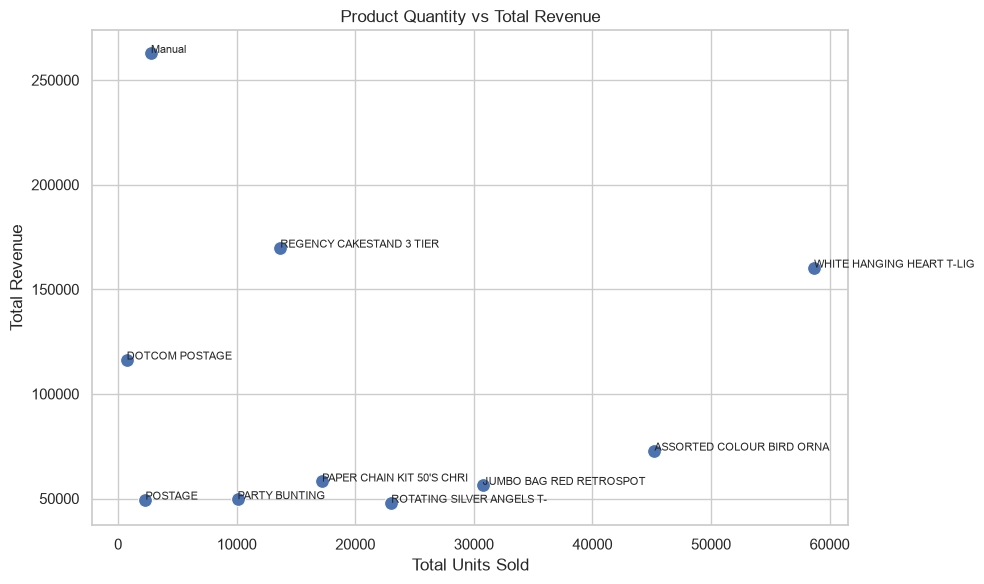

In [78]:
#Create a scatter plot....
# Create a figure for the product relationship chart
plt.figure(figsize=(10, 6))

# Compare total units sold with total revenue for each top product
sns.scatterplot(
    data=top_products,
    x="Total_Units",
    y="Total_Revenue",
    s=100
)

# Add product labels to the points
for _, row in top_products.iterrows():
    plt.annotate(
        str(row["Description"])[:25],
        (row["Total_Units"], row["Total_Revenue"]),
        fontsize=8
    )

# Add a chart title and axis labels
plt.title("Product Quantity vs Total Revenue")
plt.xlabel("Total Units Sold")
plt.ylabel("Total Revenue")

# Improve spacing
plt.tight_layout()

# Display the chart
plt.show()

 # ****** Time-Series Analysis and Sales Seasonality ******
 Time-series analysis means studying data collected over time to identify trends, patterns, seasonal changes, and unusual fluctuations.
For example, we can investigate which months generate the most revenue, which days have the most sales, and whether sales increase or decrease over the observed period.


In [88]:
# Extract the transaction year
sales_df["Year"] = sales_df["InvoiceDate"].dt.year

# Extract the month number
sales_df["Month"] = sales_df["InvoiceDate"].dt.month

# Extract the full month name
sales_df["Month_Name"] = sales_df["InvoiceDate"].dt.month_name()

# Extract the day of the month
sales_df["Day"] = sales_df["InvoiceDate"].dt.day

# Extract the weekday name
sales_df["Weekday"] = sales_df["InvoiceDate"].dt.day_name()

# Extract the date without the time component
sales_df["Sale_Date"] = sales_df["InvoiceDate"].dt.date

# Display the extracted date features
print(
    sales_df[
        ["InvoiceDate", "Year", "Month", "Month_Name",
         "Day", "Weekday", "Sale_Date"]
    ].head(20)
)

           InvoiceDate  Year  Month Month_Name  Day  Weekday   Sale_Date
0  2009-12-01 07:45:00  2009     12   December    1  Tuesday  2009-12-01
1  2009-12-01 07:45:00  2009     12   December    1  Tuesday  2009-12-01
2  2009-12-01 07:45:00  2009     12   December    1  Tuesday  2009-12-01
3  2009-12-01 07:45:00  2009     12   December    1  Tuesday  2009-12-01
4  2009-12-01 07:45:00  2009     12   December    1  Tuesday  2009-12-01
5  2009-12-01 07:45:00  2009     12   December    1  Tuesday  2009-12-01
6  2009-12-01 07:45:00  2009     12   December    1  Tuesday  2009-12-01
7  2009-12-01 07:45:00  2009     12   December    1  Tuesday  2009-12-01
8  2009-12-01 07:46:00  2009     12   December    1  Tuesday  2009-12-01
9  2009-12-01 07:46:00  2009     12   December    1  Tuesday  2009-12-01
10 2009-12-01 07:46:00  2009     12   December    1  Tuesday  2009-12-01
11 2009-12-01 07:46:00  2009     12   December    1  Tuesday  2009-12-01
12 2009-12-01 09:06:00  2009     12   December    1

In [89]:
# Analyze daily revenue
# First, calculate total revenue for each date.
# Group transactions by date and calculate daily revenue
daily_revenue = (
    sales_df.groupby("Sale_Date")["Revenue"]
    .sum()
)

# Sort dates chronologically
daily_revenue = daily_revenue.sort_index()

# Display the first five daily totals
print(daily_revenue.head())

Sale_Date
2009-12-01    54351.23
2009-12-02    63172.58
2009-12-03    73972.45
2009-12-04    40582.32
2009-12-05     9803.05
Name: Revenue, dtype: float64


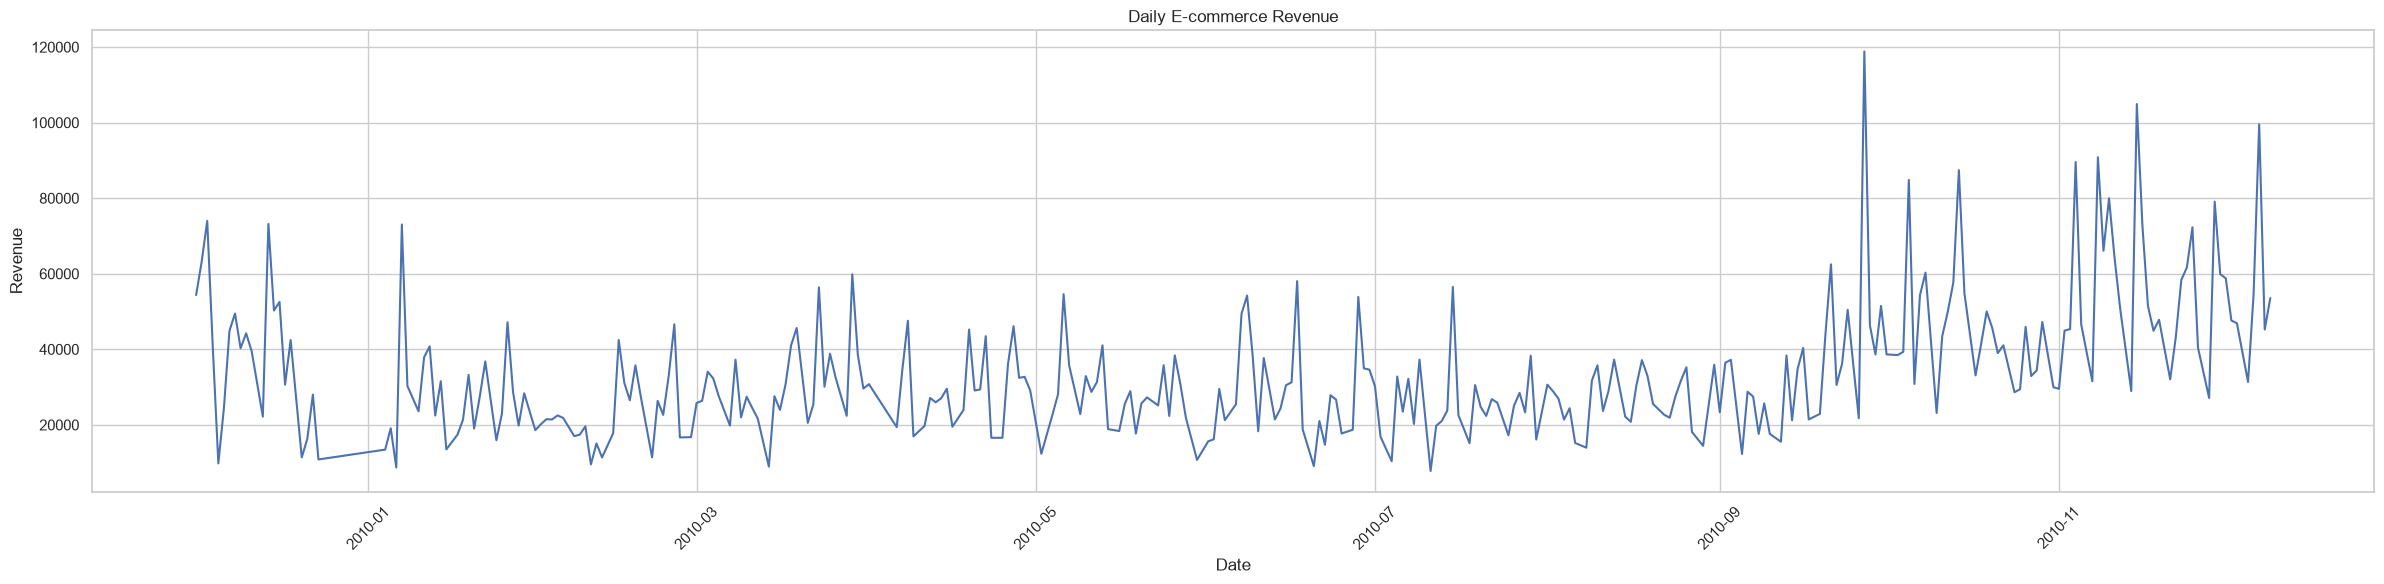

In [91]:
#Visualize daily revenue...
# Create a figure for the daily revenue chart
plt.figure(figsize=(24, 6))

# Plot revenue over time
plt.plot(
    pd.to_datetime(daily_revenue.index),
    daily_revenue.values
)

# Add a title and axis labels
plt.title("Daily E-commerce Revenue")
plt.xlabel("Date")
plt.ylabel("Revenue")

# Rotate date labels for readability
plt.xticks(rotation=45)

# Adjust spacing
plt.tight_layout()

# Display the chart
plt.show()

In [92]:
# Analyze monthly revenue
# Monthly analysis makes longer-term trends easier to identify.
# Create a year-month column for chronological grouping
sales_df["YearMonth"] = (
    sales_df["InvoiceDate"].dt.to_period("M").astype("string")
)

# Group sales by year and month
monthly_revenue = (
    sales_df.groupby("YearMonth")["Revenue"]
    .sum()
    .sort_index()
)

# Display monthly revenue
print(monthly_revenue)

YearMonth
2009-12     822483.950
2010-01     651155.112
2010-02     551878.296
2010-03     830915.261
2010-04     678875.252
2010-05     657705.500
2010-06     749537.310
2010-07     648810.270
2010-08     695251.910
2010-09     921696.991
2010-10    1161902.220
2010-11    1464293.142
2010-12     437631.020
Name: Revenue, dtype: float64


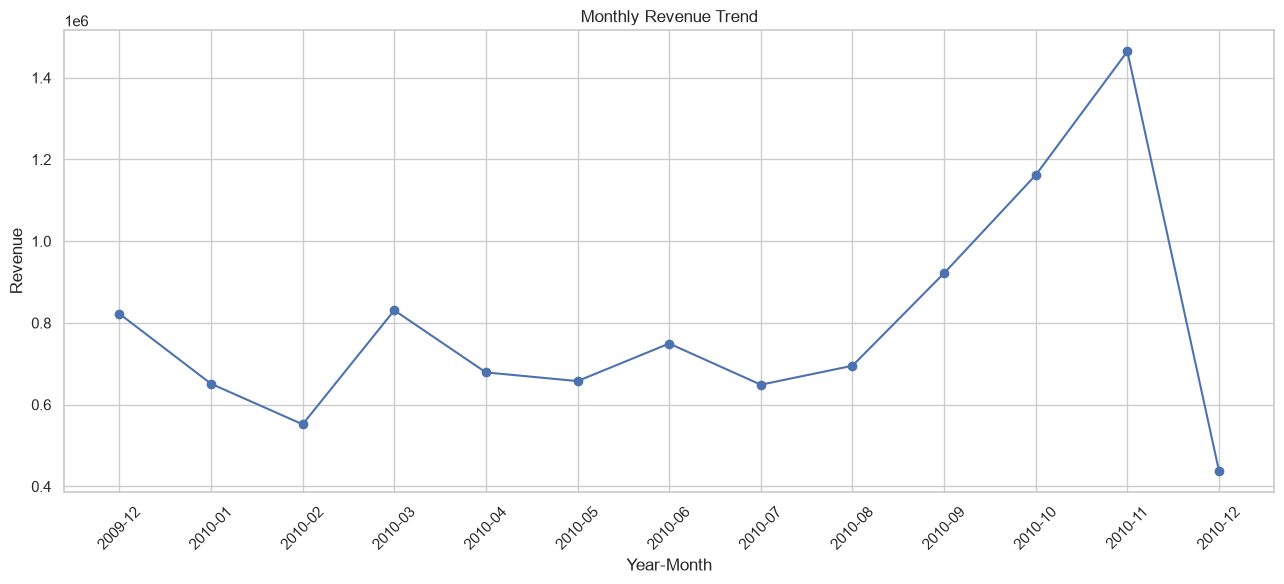

In [93]:
#Visualize monthly revenue,...
# Create a figure for the monthly revenue chart
plt.figure(figsize=(13, 6))

# Draw the monthly revenue line
plt.plot(
    monthly_revenue.index,
    monthly_revenue.values,
    marker="o"
)

# Add the title and axis labels
plt.title("Monthly Revenue Trend")
plt.xlabel("Year-Month")
plt.ylabel("Revenue")

# Rotate month labels
plt.xticks(rotation=45)

# Improve spacing
plt.tight_layout()

# Display the chart
plt.show()

In [94]:
#Identify the highest-revenue months...
# Sort monthly revenue from highest to lowest
top_months = monthly_revenue.sort_values(
    ascending=False
).head(10)

# Display the ten highest-revenue months
print("Top 10 months by revenue:")
print(top_months)

Top 10 months by revenue:
YearMonth
2010-11    1464293.142
2010-10    1161902.220
2010-09     921696.991
2010-03     830915.261
2009-12     822483.950
2010-06     749537.310
2010-08     695251.910
2010-04     678875.252
2010-05     657705.500
2010-01     651155.112
Name: Revenue, dtype: float64


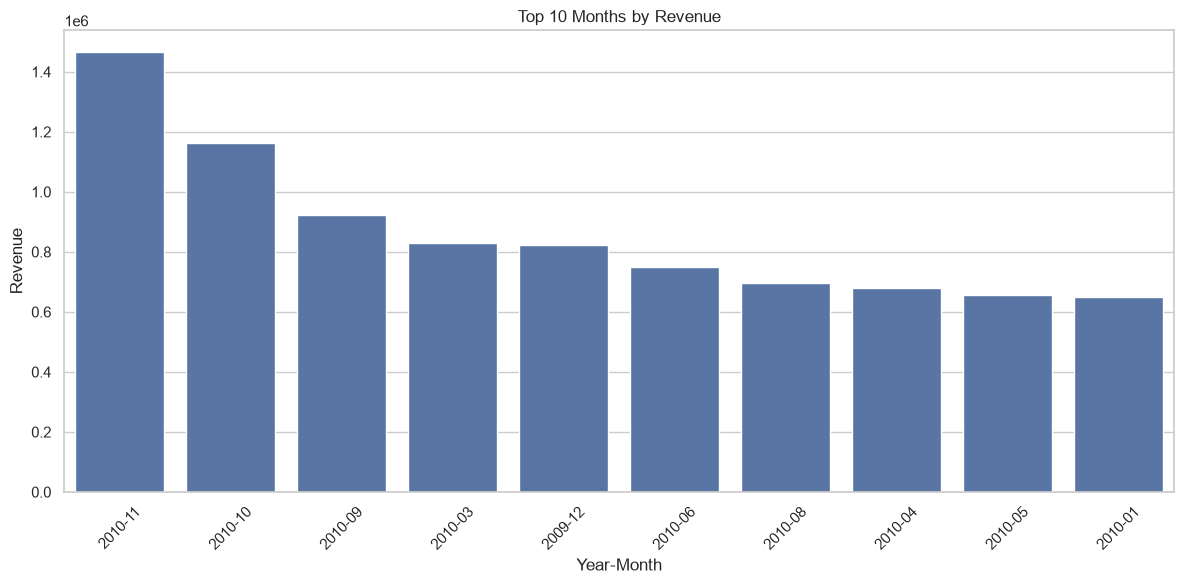

In [95]:
#Create a bar chart....
# Create a figure for the top-months chart
plt.figure(figsize=(12, 6))

# Draw a bar chart of the ten highest-revenue months
sns.barplot(
    x=top_months.index,
    y=top_months.values
)

# Add a title and axis labels
plt.title("Top 10 Months by Revenue")
plt.xlabel("Year-Month")
plt.ylabel("Revenue")

# Rotate month labels
plt.xticks(rotation=45)

# Adjust spacing
plt.tight_layout()

# Display the chart
plt.show()

In [96]:
# #Analyze sales by weekday
# Let's compare total revenue across the days of the week.

# Define weekday order from Monday through Sunday
weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

# Group revenue by weekday name
weekday_revenue = (
    sales_df.groupby("Weekday")["Revenue"]
    .sum()
    .reindex(weekday_order)
)

# Display revenue by weekday
print(weekday_revenue)

Weekday
Monday       1860809.825
Tuesday      2002003.301
Wednesday    1745382.103
Thursday     2097097.802
Friday       1533319.022
Saturday        9803.050
Sunday       1023721.131
Name: Revenue, dtype: float64


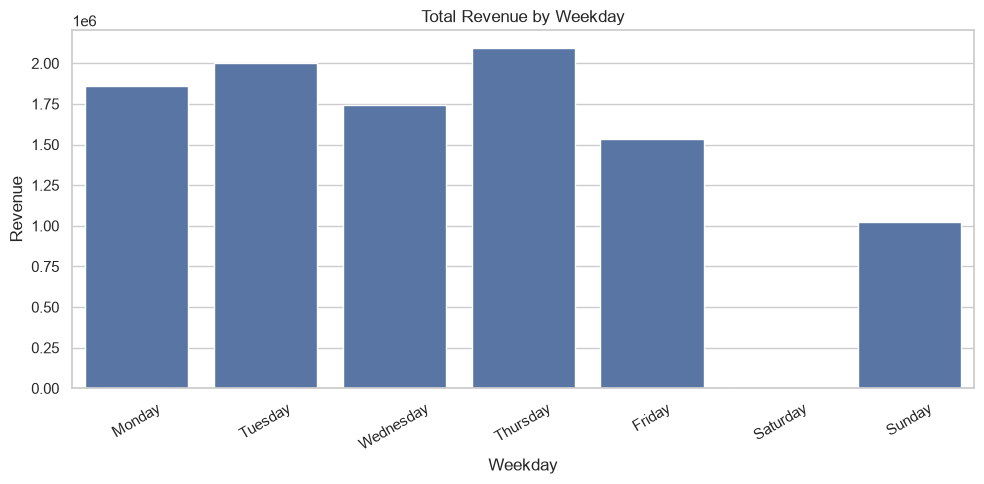

In [97]:
#Visualize weekday revenue....
# Create a figure for the weekday chart
plt.figure(figsize=(10, 5))

# Draw a bar chart in weekday order
sns.barplot(
    x=weekday_revenue.index,
    y=weekday_revenue.values
)

# Add the title and axis labels
plt.title("Total Revenue by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Revenue")

# Rotate labels for readability
plt.xticks(rotation=30)

# Adjust spacing
plt.tight_layout()

# Display the chart
plt.show()

In [98]:
#Compare monthly revenue across years.....
# Group revenue by year and calendar month
year_month_revenue = (
    sales_df.groupby(["Year", "Month"])["Revenue"]
    .sum()
    .reset_index()
)

# Display the monthly revenue grouped by year
print(year_month_revenue.head(12))

    Year  Month      Revenue
0   2009     12   822483.950
1   2010      1   651155.112
2   2010      2   551878.296
3   2010      3   830915.261
4   2010      4   678875.252
5   2010      5   657705.500
6   2010      6   749537.310
7   2010      7   648810.270
8   2010      8   695251.910
9   2010      9   921696.991
10  2010     10  1161902.220
11  2010     11  1464293.142


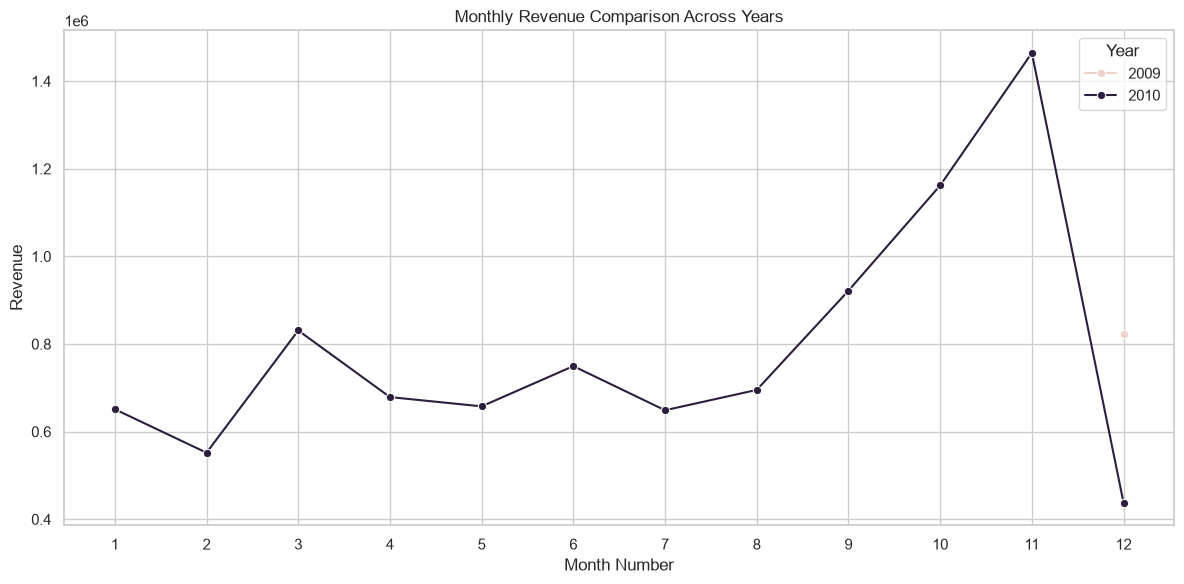

In [99]:
#Visualize the comparison.....
# Create a figure for the seasonal comparison
plt.figure(figsize=(12, 6))

# Plot one line for each year
sns.lineplot(
    data=year_month_revenue,
    x="Month",
    y="Revenue",
    hue="Year",
    marker="o"
)

# Set the month axis to January through December
plt.xticks(range(1, 13))

# Add the title and axis labels
plt.title("Monthly Revenue Comparison Across Years")
plt.xlabel("Month Number")
plt.ylabel("Revenue")

# Display the legend
plt.legend(title="Year")

# Adjust spacing
plt.tight_layout()

# Display the chart
plt.show()

# ***Advanced Business KPIs and Sales Performance Dashboard***

In [100]:
#Load the dataset.....
# Import Pandas for data analysis
import pandas as pd

# Import NumPy for numerical calculations
import numpy as np

# Import Matplotlib for dashboard charts
import matplotlib.pyplot as plt

# Import Seaborn for statistical visualizations
import seaborn as sns

# Import Path to manage output folders
from pathlib import Path

# Set the chart style
sns.set_theme(style="whitegrid")

# Load the positive-sales dataset
sales_df = pd.read_csv(
    "../outputs/ecommerce_positive_sales.csv",
    parse_dates=["InvoiceDate"]
)

# Calculate revenue if it is not already present
if "Revenue" not in sales_df.columns:
    sales_df["Revenue"] = sales_df["Quantity"] * sales_df["Price"]

# Display the dataset dimensions
print("Dataset shape:", sales_df.shape)

# Display the first five records
print(sales_df.head())

Dataset shape: (504731, 12)
  Invoice StockCode                          Description  Quantity  \
0  489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1  489434    79323P                   PINK CHERRY LIGHTS        12   
2  489434    79323W                  WHITE CHERRY LIGHTS        12   
3  489434     22041          RECORD FRAME 7" SINGLE SIZE        48   
4  489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24   

          InvoiceDate  Price  Customer ID         Country  Revenue  Year  \
0 2009-12-01 07:45:00   6.95      13085.0  United Kingdom     83.4  2009   
1 2009-12-01 07:45:00   6.75      13085.0  United Kingdom     81.0  2009   
2 2009-12-01 07:45:00   6.75      13085.0  United Kingdom     81.0  2009   
3 2009-12-01 07:45:00   2.10      13085.0  United Kingdom    100.8  2009   
4 2009-12-01 07:45:00   1.25      13085.0  United Kingdom     30.0  2009   

   Month YearMonth  
0     12   2009-12  
1     12   2009-12  
2     12   2009-12  
3     12  

/var/folders/ts/3rlmcq110z96z6tjzjkm17800000gn/T/ipykernel_67894/3339044168.py:21: DtypeWarning: Columns (0: Invoice) have mixed types. Specify dtype option on import or set low_memory=False.
  sales_df = pd.read_csv(


<!-- Calculate advanced business KPIs
We will calculate these metrics:
KPI	Business purpose
Total revenue	Measures total recorded sales value
Total units sold	Measures sales volume
Total orders	Counts distinct invoices
Average order value	Measures average revenue per invoice
Unique customers	Counts identified customers
Revenue per identified customer	Measures average revenue per identified customer
Top country	Identifies the highest-revenue country -->

<!-- Calculate advanced business KPIs
We will calculate these metrics:
KPI	Business purpose
Total revenue	Measures total recorded sales value
Total units sold	Measures sales volume
Total orders	Counts distinct invoices
Average order value	Measures average revenue per invoice
Unique customers	Counts identified customers
Revenue per identified customer	Measures average revenue per identified customer
Top country	Identifies the highest-revenue country -->

In [101]:
# Calculate advanced business KPIs
# We will calculate these metrics:
# KPI	                   Business purpose
# Total revenue	    Measures total recorded sales value
# Total units sold	Measures sales volume
# Total orders	    Counts distinct invoices
# Average order value	Measures average revenue per invoice
# Unique customers	Counts identified customers
# Revenue per identified customer 	Measures average revenue per identified customer
# Top country	                        Identifies the highest-revenue country

In [102]:
#KPI calculations...
# Calculate total revenue from positive sales
total_revenue = sales_df["Revenue"].sum()

# Calculate the total quantity sold
total_units_sold = sales_df["Quantity"].sum()

# Count distinct invoices
total_orders = sales_df["Invoice"].nunique()

# Calculate average order value
average_order_value = (
    total_revenue / total_orders
    if total_orders > 0
    else 0
)

# Count distinct customers with recorded customer IDs
unique_customers = sales_df["Customer ID"].nunique()

# Keep only records with identified customers
identified_sales = sales_df.dropna(
    subset=["Customer ID"]
).copy()

# Calculate revenue generated by identified customers
identified_revenue = identified_sales["Revenue"].sum()

# Calculate average revenue per identified customer
revenue_per_customer = (
    identified_revenue / unique_customers
    if unique_customers > 0
    else 0
)

# Calculate revenue by country
country_revenue = (
    sales_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

# Identify the highest-revenue country
top_country = (
    country_revenue.index[0]
    if not country_revenue.empty
    else "No data"
)

# Display the calculated KPIs
print("ECOMMERCE BUSINESS PERFORMANCE")
print("-" * 40)
print(f"Total Revenue: {total_revenue:,.2f}")
print(f"Total Units Sold: {total_units_sold:,.0f}")
print(f"Total Orders: {total_orders:,}")
print(f"Average Order Value: {average_order_value:,.2f}")
print(f"Unique Identified Customers: {unique_customers:,}")
print(f"Revenue per Identified Customer: {revenue_per_customer:,.2f}")
print(f"Top Country by Revenue: {top_country}")

ECOMMERCE BUSINESS PERFORMANCE
----------------------------------------
Total Revenue: 10,272,136.23
Total Units Sold: 5,812,948
Total Orders: 20,953
Average Order Value: 490.25
Unique Identified Customers: 4,312
Revenue per Identified Customer: 2,040.41
Top Country by Revenue: United Kingdom


In [103]:
# . Prepare the chart data
# Before building the dashboard, let's prepare monthly revenue and the top products.
# Create a year-month column from the invoice date
sales_df["YearMonth"] = (
    sales_df["InvoiceDate"].dt.to_period("M").astype("string")
)

# Calculate total revenue for each month
monthly_revenue = (
    sales_df.groupby("YearMonth")["Revenue"]
    .sum()
    .sort_index()
)

# Calculate revenue for each product description
product_revenue = (
    sales_df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

# Exclude placeholder descriptions if present
product_revenue = product_revenue[
    ~product_revenue.index.isin(["Unknown", ""])
]

# Select the top 10 products
top_products = product_revenue.head(10)

# Calculate revenue for each country
country_revenue = (
    sales_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

# Select the top 10 countries
top_countries = country_revenue.head(10)

# Display the prepared monthly revenue data
print(monthly_revenue.tail())

YearMonth
2010-08     695251.910
2010-09     921696.991
2010-10    1161902.220
2010-11    1464293.142
2010-12     437631.020
Name: Revenue, dtype: float64


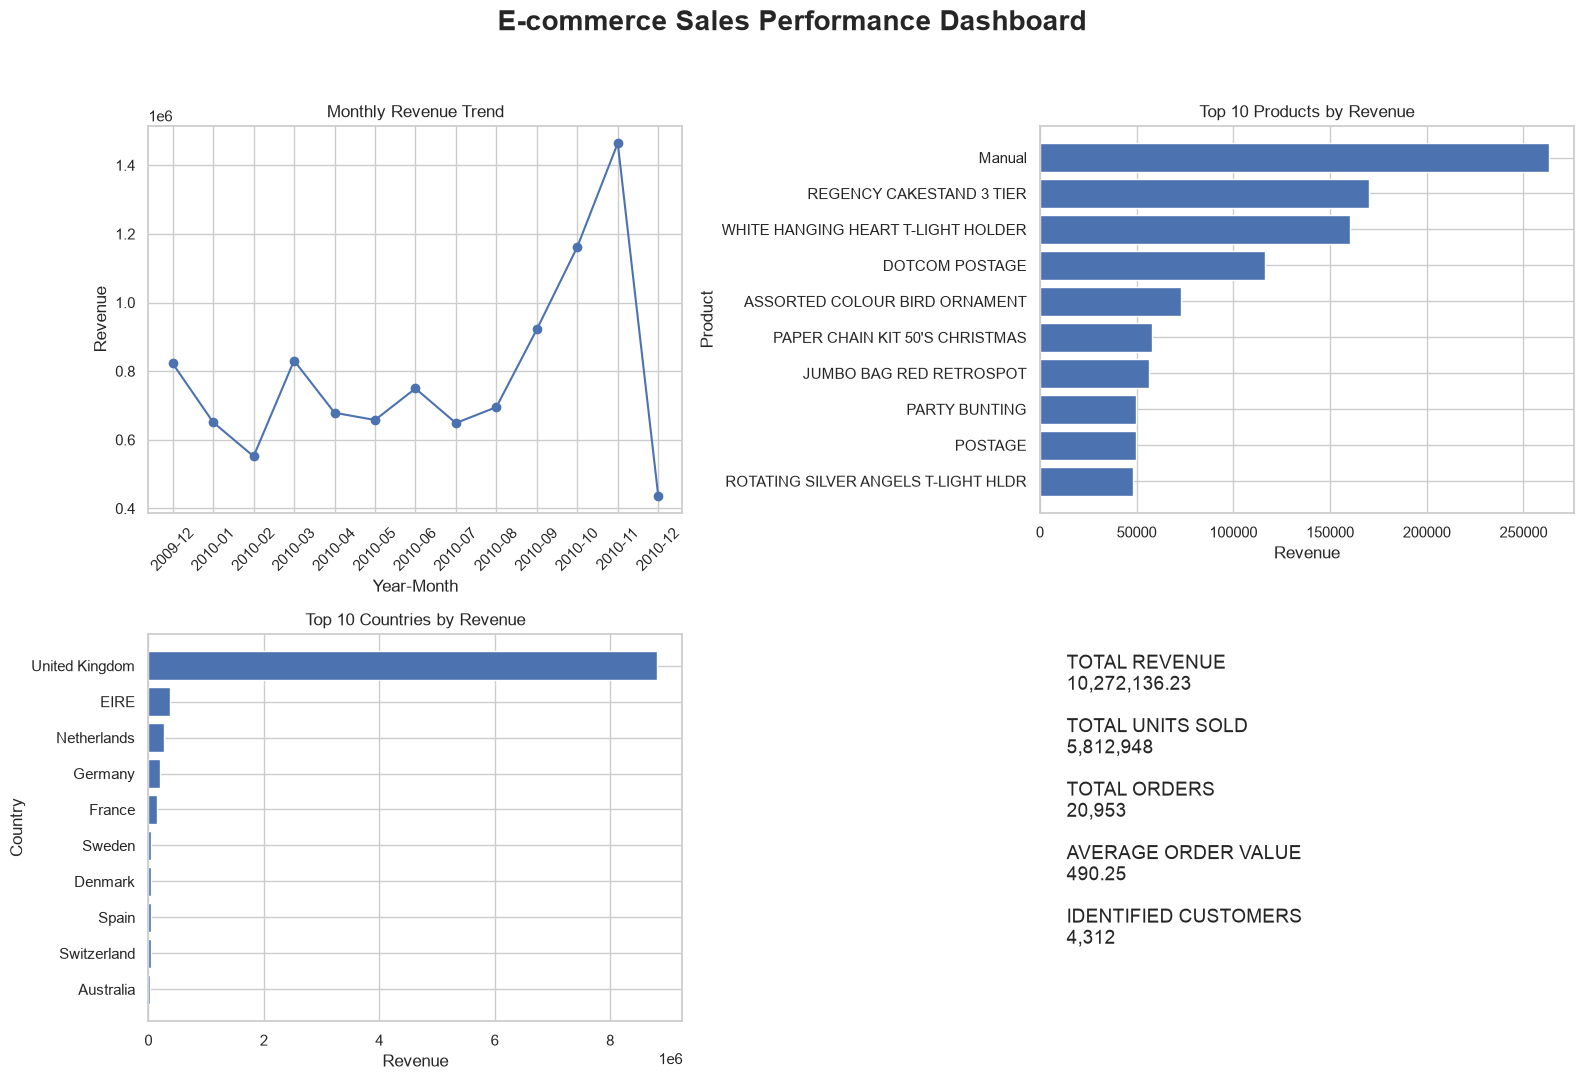

In [104]:
# Build the sales performance dashboard
# We will use Matplotlib's subplots() function to arrange multiple charts in one figure.
# Create a dashboard with two rows and two columns
fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 11)
)

# Add an overall title to the dashboard
fig.suptitle(
    "E-commerce Sales Performance Dashboard",
    fontsize=20,
    fontweight="bold"
)

# --------------------------------------------------
# Chart 1: Monthly revenue trend
# --------------------------------------------------

# Plot monthly revenue as a line chart
axes[0, 0].plot(
    monthly_revenue.index,
    monthly_revenue.values,
    marker="o"
)

# Add the chart title and axis labels
axes[0, 0].set_title("Monthly Revenue Trend")
axes[0, 0].set_xlabel("Year-Month")
axes[0, 0].set_ylabel("Revenue")

# Rotate the month labels
axes[0, 0].tick_params(axis="x", rotation=45)

# --------------------------------------------------
# Chart 2: Top 10 products by revenue
# --------------------------------------------------

# Reverse the order so the largest bar appears at the top
product_chart = top_products.sort_values()

# Plot product revenue as a horizontal bar chart
axes[0, 1].barh(
    product_chart.index.astype(str),
    product_chart.values
)

# Add the chart title and axis labels
axes[0, 1].set_title("Top 10 Products by Revenue")
axes[0, 1].set_xlabel("Revenue")
axes[0, 1].set_ylabel("Product")

# --------------------------------------------------
# Chart 3: Top 10 countries by revenue
# --------------------------------------------------

# Reverse the order for a clearer horizontal chart
country_chart = top_countries.sort_values()

# Plot country revenue
axes[1, 0].barh(
    country_chart.index.astype(str),
    country_chart.values
)

# Add the chart title and axis labels
axes[1, 0].set_title("Top 10 Countries by Revenue")
axes[1, 0].set_xlabel("Revenue")
axes[1, 0].set_ylabel("Country")

# --------------------------------------------------
# Chart 4: KPI summary
# --------------------------------------------------

# Turn off the axes because this panel displays text
axes[1, 1].axis("off")

# Create text containing the main business KPIs
kpi_text = (
    f"TOTAL REVENUE\n{total_revenue:,.2f}\n\n"
    f"TOTAL UNITS SOLD\n{total_units_sold:,.0f}\n\n"
    f"TOTAL ORDERS\n{total_orders:,}\n\n"
    f"AVERAGE ORDER VALUE\n{average_order_value:,.2f}\n\n"
    f"IDENTIFIED CUSTOMERS\n{unique_customers:,}"
)

# Place the KPI text inside the fourth panel
axes[1, 1].text(
    0.05, 0.95,
    kpi_text,
    transform=axes[1, 1].transAxes,
    fontsize=14,
    verticalalignment="top"
)

# Adjust spacing between dashboard panels
plt.tight_layout(rect=[0, 0, 1, 0.95])

# Create the output folder if it does not exist
output_folder = Path("../outputs")
output_folder.mkdir(parents=True, exist_ok=True)

# Save the dashboard as a high-resolution PNG image
plt.savefig(
    output_folder / "ecommerce_sales_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

# Display the complete dashboard
plt.show()